## TP2-Adaptive filters Least Mean Squares (LMS) for Echo Cancellation

Nom : Boutayeb Fadi - Mikoungu Samuel

In [32]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import lfilter

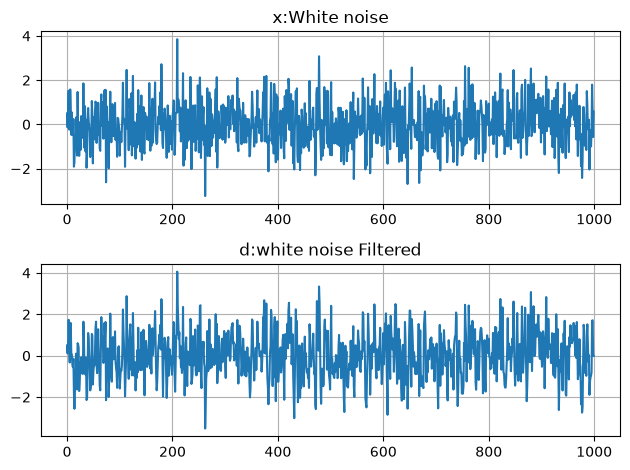

In [31]:
#ToDo2:
N = 1000
np.random.seed(42)
white_noise = np.random.randn(N) #bruit blanc

h = np.array([1, 0.5, 0.1, -0.2]) #impulse response

d=lfilter(h, [1], white_noise) # filtre white noise with h

plt.subplot(2, 1, 1)    
plt.plot(white_noise)
plt.title("x:White noise")
plt.grid()

plt.subplot(2, 1, 2)
plt.plot(d)
plt.title("d:white noise Filtered")
plt.grid()

plt.tight_layout()
plt.show()

In [30]:
#ToDo3:
def algoLMS(x,d,M, mu):
    N = len(x)
    w = np.zeros(M)
    y = np.zeros(N)
    e = np.zeros(N) 
    
    for k in range(M, N):
        x_k = x[k:k-M:-1]  #Input vector
        y[k] = np.dot(w, x_k)
        e[k] = d[k] - y[k]  #Error 
        w = w+mu*e[k]*x_k  #Update weights
    
    return y, e, w

#print(algoLMS(white_noise, d, 4, 0.01))

In [40]:
#ToDo4:
M = 4
mu = 0.01
N = len(white_noise)

w = np.zeros(M)
y = np.zeros(N)
e = np.zeros(N)
w_history = np.zeros((N, M))

# LMS algorithm
y, e, w = algoLMS(white_noise, d, M, mu)

print("True coefficients:", h)
print("Estimated coefficients:", w)

True coefficients: [ 1.   0.5  0.1 -0.2]
Estimated coefficients: [ 0.99994406  0.49996713  0.09999073 -0.19998231]


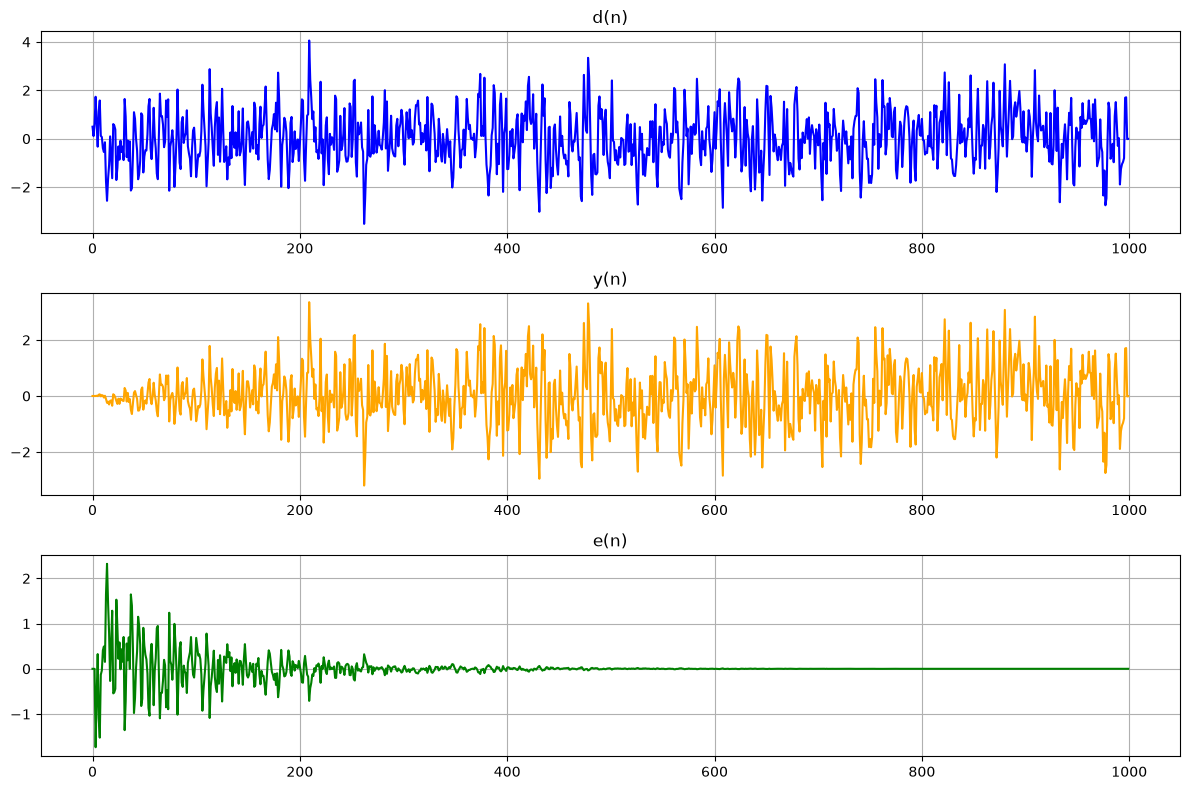

In [37]:
# plot e(n) d(n) y(n)

plt.figure(figsize=(12, 8))
plt.subplot(3, 1, 1)
plt.plot(d, label='d(n)', color='blue')
plt.title('d(n)')
plt.grid()
plt.subplot(3, 1, 2)
plt.plot(y, label='y(n)', color='orange')
plt.title('y(n)')
plt.grid()
plt.subplot(3, 1, 3)
plt.plot(e, label='e(n)', color='green')
plt.title('e(n)')
plt.grid()
plt.tight_layout()


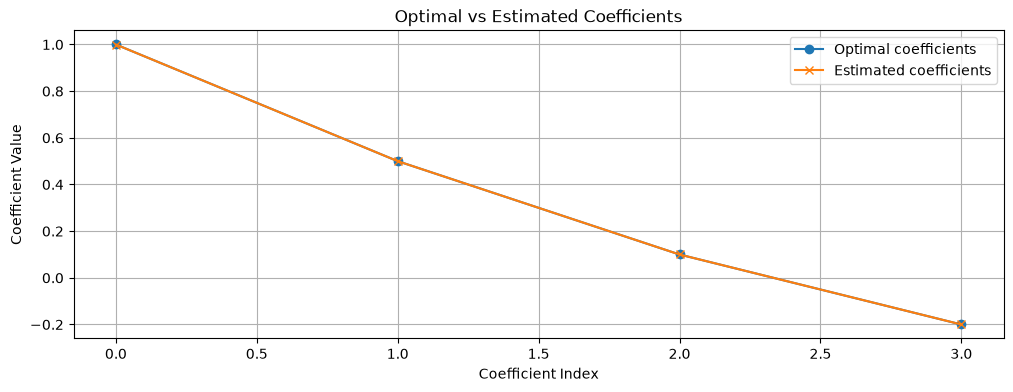

In [39]:
#plot w optimal and w estimated
w_opt=h #we showed it theory
plt.figure(figsize=(12, 4))
plt.plot(w_opt, label='Optimal coefficients', marker='o')
plt.plot(w, label='Estimated coefficients', marker='x')
plt.title('Optimal vs Estimated Coefficients')
plt.xlabel('Coefficient Index')
plt.ylabel('Coefficient Value')
plt.legend()
plt.grid()
plt.show()

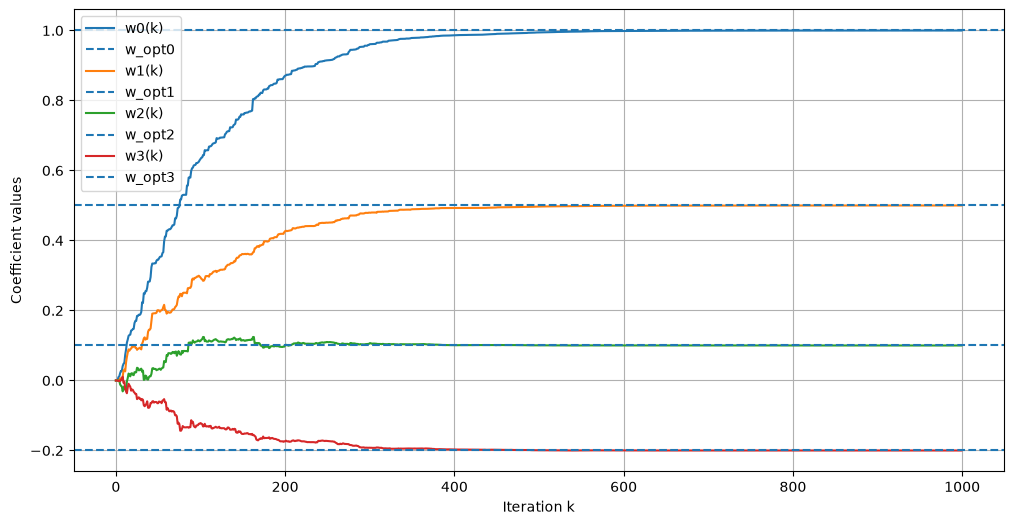

In [62]:
N = 1000
M = 4
mu = 0.01

x = np.random.randn(N)
d = lfilter(h, [1], x)

w = np.zeros(M)
w_history = np.zeros((N, M))

for k in range(M-1, N):
    x_vec = x[k-M+1:k+1][::-1]
    y = np.dot(w, x_vec)
    e = y-d[k]
    w = w - mu * e * x_vec
    w_history[k] = w

# Plot convergence
plt.figure(figsize=(12, 6))

for i in range(M):
    plt.plot(w_history[:, i], label=f'w{i}(k)')
    plt.axhline(h[i], linestyle='--', label=f'w_opt{i}')

plt.xlabel('Iteration k')
plt.ylabel('Coefficient values')
plt.legend()
plt.grid()
plt.show()


 checkpoint 1

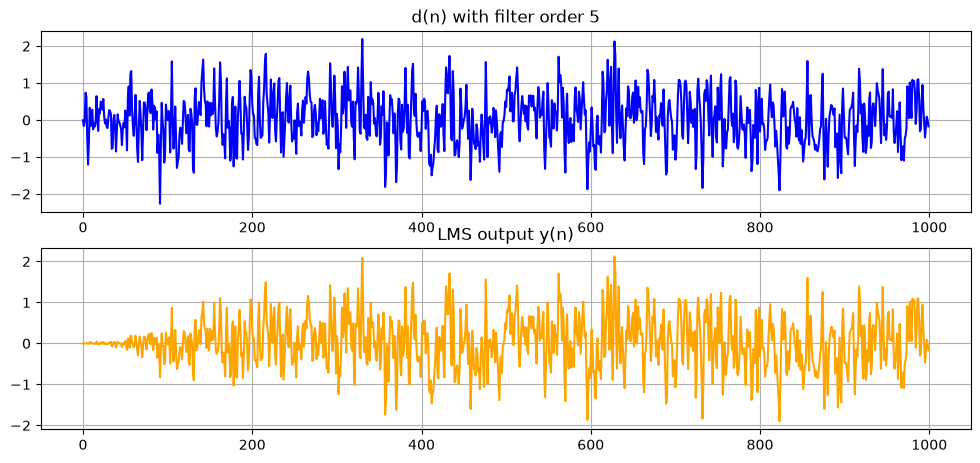

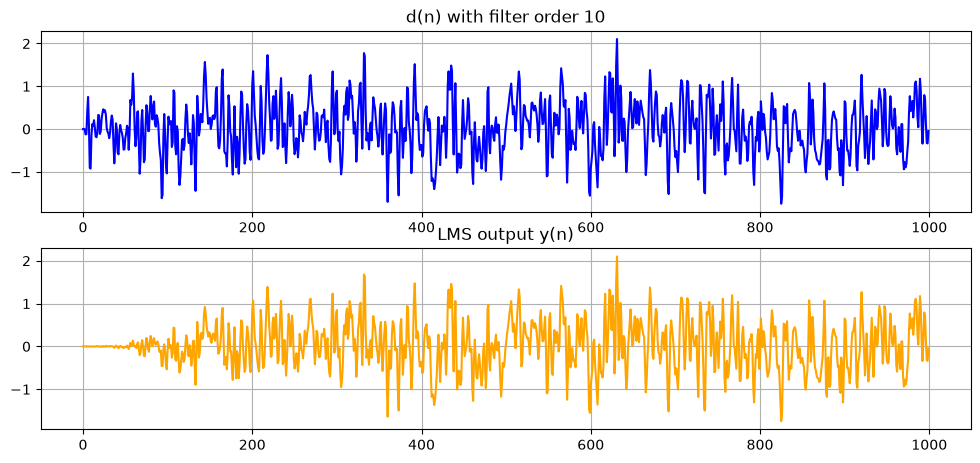

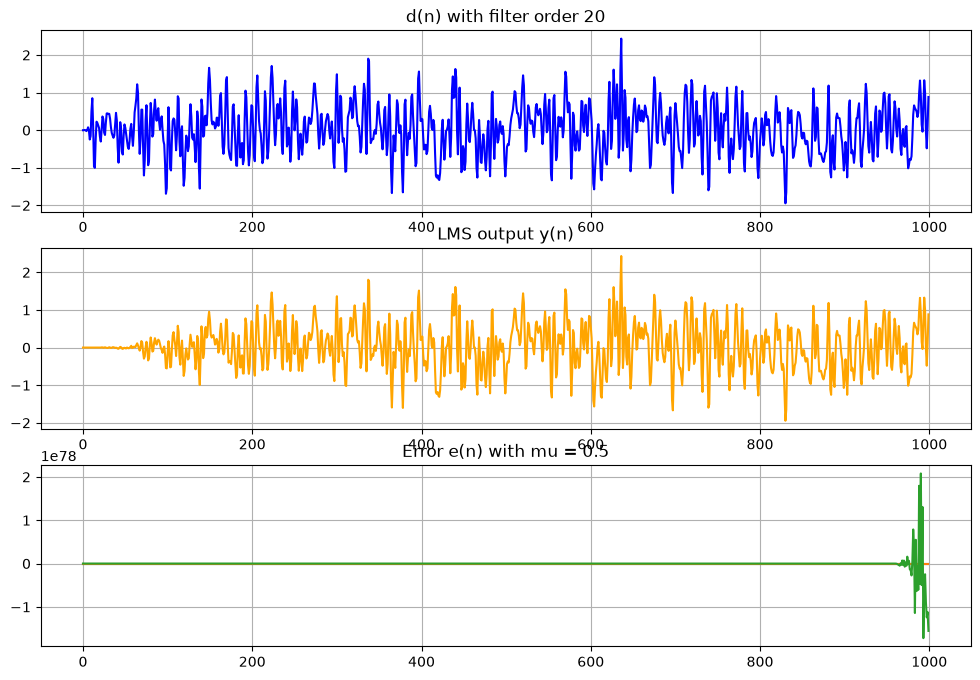

In [64]:
#ToDo5:
from scipy.signal import firwin

f=0.5
P=[5,10,20]
mu=[0.01,0.1,0.5]
N=1000
white_noise = np.random.randn(N)

#impact of the filter order
for p in P:
    b = firwin(p-1,f)
    d = lfilter(b,[1],white_noise)

    y,e,w =algoLMS(white_noise,d,p+1,0.01)

    plt.figure(figsize=(12, 8))

    plt.subplot(3, 1, 1)
    #d
    plt.plot(d, label='d(n)', color='blue')
    plt.title(f'd(n) with filter order {p}')
    plt.grid()

    plt.subplot(3, 1, 2)
    #y
    plt.plot(y, label='y(n)', color='orange')
    plt.title('LMS output y(n)')
    plt.grid()

#we fix P=5

p = 5
b = firwin(p-1, f)
d = lfilter(b, [1], white_noise)

for m in mu:
    y,e,w = algoLMS(white_noise, d, p + 1, m)

    plt.subplot(3, 1,3)
    plt.plot(e)
    plt.title(f'Error e(n) with mu = {m}')
    plt.grid()
plt.show()


checkpoint 2